In [1]:
!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import matplotlib.pyplot as plt
import numpy as np

**Load MNIST data**

In [3]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


**Normaliza pixel values to [0,1]**

In [4]:
x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0

**Add channel dimension**

In [5]:
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

**print some of data before starting**

In [6]:
print("shape of x_train:",x_train.shape)
print("shape of y_train:",y_train.shape)
print("\nFirst 5 labels:",y_train[:5])

shape of x_train: (60000, 28, 28, 1)
shape of y_train: (60000,)

First 5 labels: [5 0 4 1 9]


**plot first 5 images**

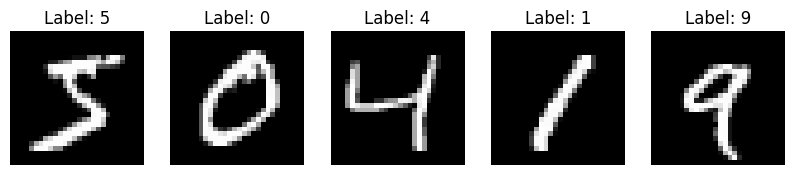

In [7]:
plt.figure(figsize=(10,2))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_train[i].reshape(28,28),cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

In [8]:
y_train_cat=tf.keras.utils.to_categorical(y_train,num_classes=10)
y_test_cat=tf.keras.utils.to_categorical(y_test,num_classes=10)

**Build the CNN model**

In [9]:
model=Sequential([
    Conv2D(32,kernel_size=(3,3),activation='relu',padding='same',input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,kernel_size=(3,3),activation='relu',padding='same'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Compile the model**

In [10]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [11]:
from keras.callbacks import EarlyStopping
early_stopping=EarlyStopping(monitor='val_loss',min_delta=0.001,patience=5,restore_best_weights=True)

In [14]:
history=model.fit(x_train,y_train_cat,
          validation_data=(x_test,y_test_cat),
          epochs=10,
          batch_size=128,
          callbacks=[early_stopping])

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 71s 149ms/step - accuracy: 0.9470 - loss: 0.1808 - val_accuracy: 0.9825 - val_loss: 0.0594
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 72s 153ms/step - accuracy: 0.9847 - loss: 0.0491 - val_accuracy: 0.9872 - val_loss: 0.0401
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 69s 148ms/step - accuracy: 0.9888 - loss: 0.0360 - val_accuracy: 0.9864 - val_loss: 0.0375
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 72s 153ms/step - accuracy: 0.9915 - loss: 0.0273 - val_accuracy: 0.9884 - val_loss: 0.0330
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 72s 153ms/step - accuracy: 0.9932 - loss: 0.0208 - val_accuracy: 0.9909 - val_loss: 0.0300
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 153ms/step - accuracy: 0.9952 - loss: 0.0152 - val_accuracy: 0.9896 - val_loss: 0.0346
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 77s 163ms/step - accuracy: 0.9962 - loss: 0.0118 - val_accuracy: 0.9893 - val_loss: 0.0339
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 77s 164ms/step - accuracy: 0.9965 - loss: 0

**Evaluate on test data**

In [15]:
test_loss,test_acc=model.evaluate(x_test,y_test_cat)
print("Test accuracy:",test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9909 - loss: 0.0300
Test accuracy: 0.9908999800682068


**make prediction on first 5 test images**

In [16]:
predicted=model.predict(x_test[:5])
predicted=np.argmax(predicted,axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


**print actual vs predicted**

In [19]:
print("\nActual labels : ",y_test[:5])
print("Predicted labels:",predicted)


Actual labels :  [7 2 1 0 4]
Predicted labels: [7 2 1 0 4]


**plot the image with predicted labels**

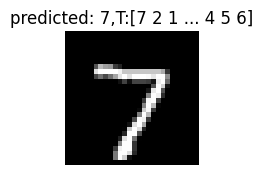

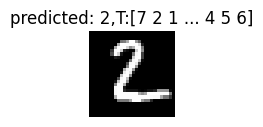

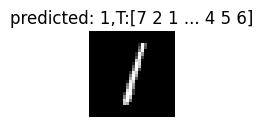

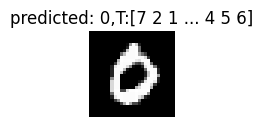

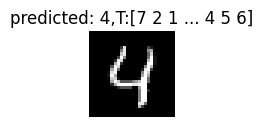

In [20]:
plt.figure(figsize=(10,2))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_test[i].reshape(28,28),cmap='gray')
    plt.title(f"predicted: {predicted[i]},T:{y_test}")
    plt.axis('off')
    plt.show()
